# 1.10. Visualize metric absolute response to cumulative image degradation

This notebook:
1. Reads metric absolute response artifacts generated by notebook 1.9.
2. Compares normalized metric trajectories, observed score ranges, and first-step responses across degradation types.
3. Relates saved image snapshots to metric response curves for visual interpretation.

In [1]:
from pathlib import Path

from utils.metric_absolute_response_plot import (
    load_absolute_response_artifacts,
    plot_initial_response_vs_mae,
    plot_normalized_ranges,
    plot_normalized_trajectories,
    plot_snapshot_response,
)
from utils.validate_config import (
    load_degradation_plot_config,
    load_yaml_config,
    require_config_directory,
    require_config_membership,
    require_config_value,
)

In [2]:
config = load_yaml_config("degradation_config.yaml")
analysis_dir = require_config_directory(config, "analysis_out_dir")

channels = require_config_value(config, "channels")
input_channel = require_config_membership(config, "input_channel", "channels")
target_channels = [channel for channel in channels if channel != input_channel]
reference_channel = target_channels[0]

analysis_output_dir = (
    analysis_dir / "metric_absolute_response_analysis" / reference_channel
)
results_output_dir = Path("results") / "metric_absolute_response_analysis"
plot_output_dir = (
    Path("results") / "metric_absolute_response_analysis" / reference_channel
)

metric_results, normalized_metric_results, response_configuration = (
    load_absolute_response_artifacts(
        analysis_output_dir=analysis_output_dir, 
        results_output_dir=results_output_dir)
)

In [3]:
normalized_metric_results.head()

,reference_channel,transform_name,iteration,metric_name,metric_value,lower_bound,upper_bound,clipped_metric_value,normalized_metric_value
0,OrigER,gauss_noise,1,ssim,0.983872,0.0,1.0,0.983872,0.983872
1,OrigER,gauss_noise,1,psnr,48.245155,0.0,50.0,48.245155,0.964903
2,OrigER,gauss_noise,1,mae,0.003130,0.0,1.0,0.003130,0.996870
3,OrigER,gauss_noise,1,lpips,0.045597,0.0,1.0,0.045597,0.954403
4,OrigER,gauss_noise,1,dists,0.151885,0.0,1.0,0.151885,0.848115


In [4]:
{
    "metric_rows": len(metric_results),
    "normalized_metric_rows": len(normalized_metric_results),
    **response_configuration,
}

{'metric_rows': 21000,
 'normalized_metric_rows': 21000,
 'iterations': 500,
 'snapshot_interval': 10,
 'noise_fraction': 0.01,
 'reference_min': 0.0032959487289190292,
 'reference_max': 0.4129701554775238,
 'reference_contrast': 0.40967419743537903,
 'gaussian_noise_std': 0.0040967419743537905,
 'morphology_kernel': '3x3 ellipse',
 'morphology_iterations_per_step': 1,
 'reference_channel': 'OrigER'}

In [5]:
degradation_plot_config = load_degradation_plot_config("degradation_plot_config.yaml")

metric_order = degradation_plot_config["metrics"]["order"]
metric_labels = degradation_plot_config["metrics"]["labels"]
metric_palette = degradation_plot_config["metrics"]["palette"]
transform_order = degradation_plot_config["transforms"]["order"]
transform_labels = degradation_plot_config["transforms"]["labels"]

observed_transforms = set(normalized_metric_results["transform_name"].unique())
unconfigured_transforms = observed_transforms.difference(transform_order)
if unconfigured_transforms:
    raise ValueError(
        "Metric results contain transforms missing from the plot config: "
        f"{sorted(unconfigured_transforms)}"
    )

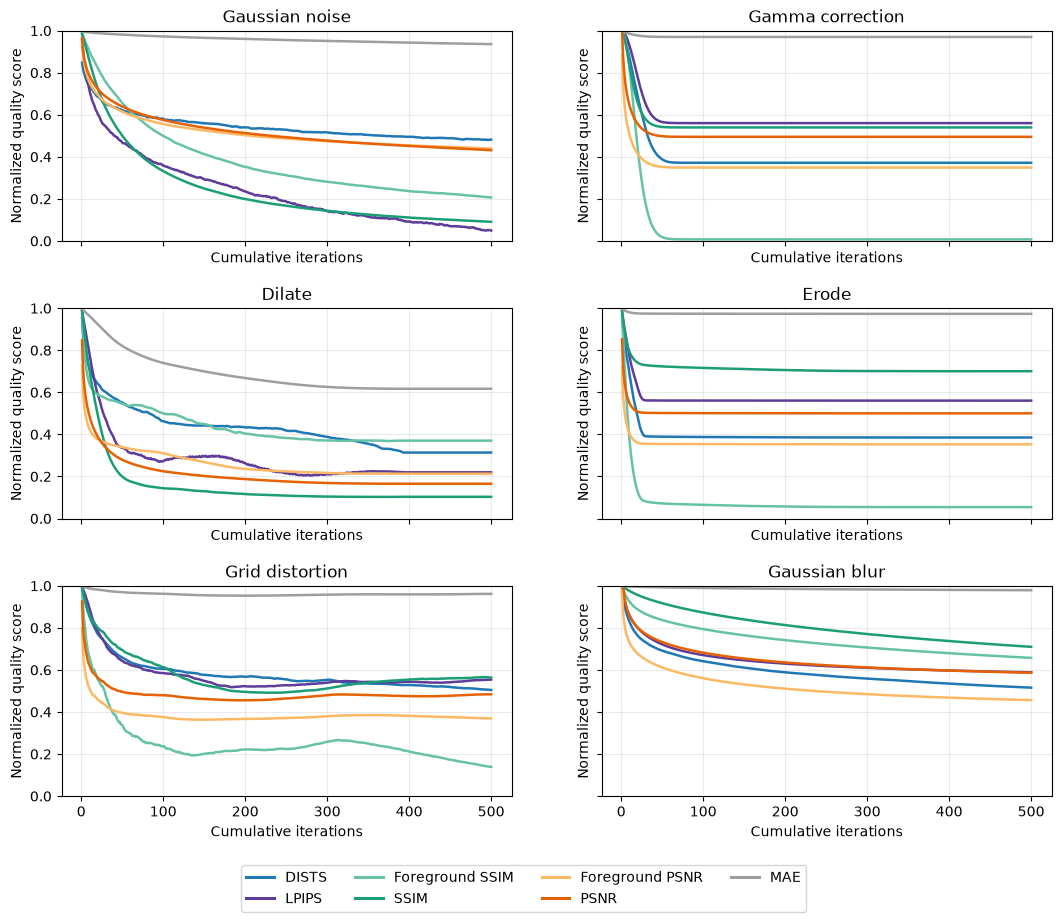

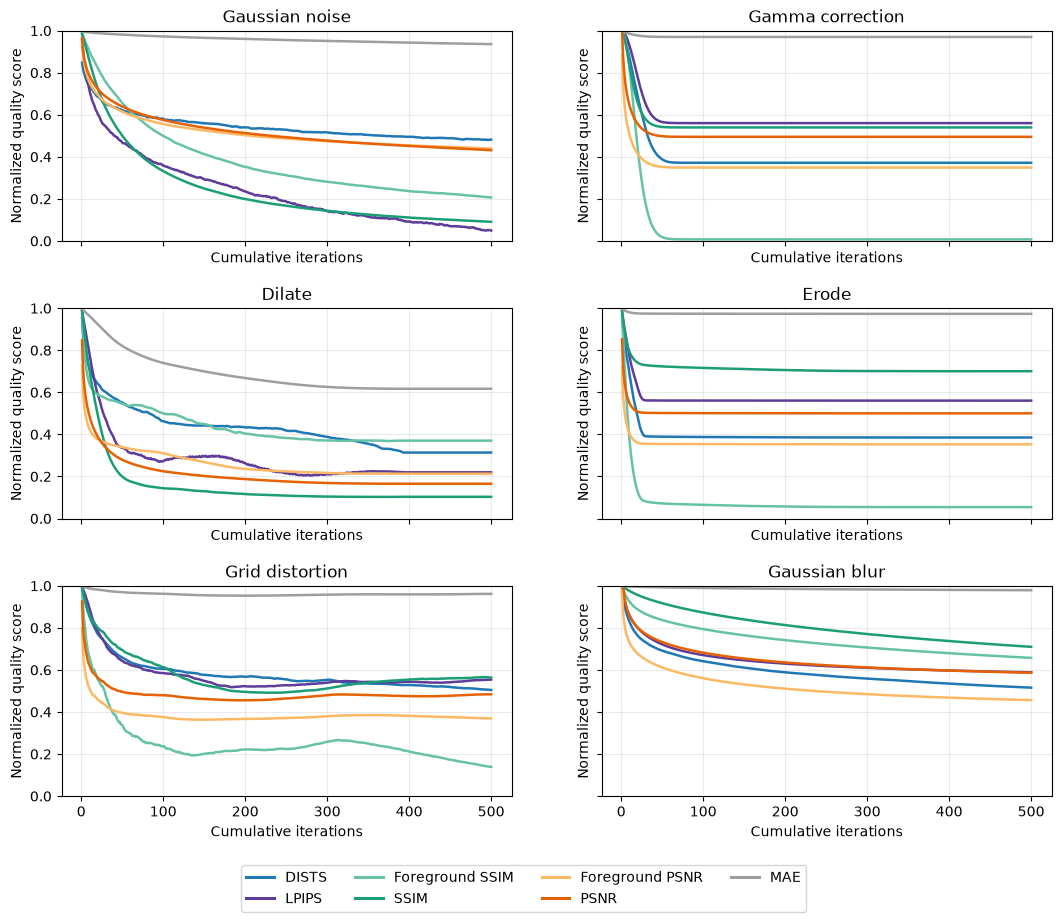

In [6]:
plot_normalized_trajectories(
    normalized_metric_results,
    metric_order=metric_order,
    metric_labels=metric_labels,
    metric_palette=metric_palette,
    transform_order=transform_order,
    transform_labels=transform_labels,
    output_path=plot_output_dir / "normalized_metric_trajectories_by_degradation.png",
)

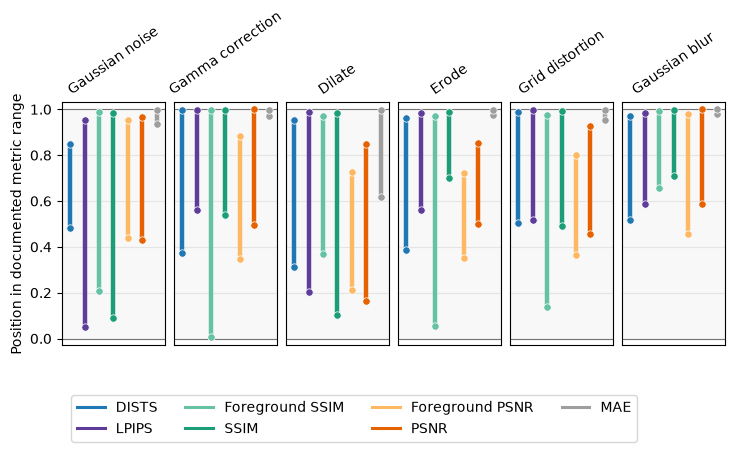

,transform_name,metric_name,empirical_low,empirical_high
0,gauss_noise,ssim,0.091057,0.983872
1,gauss_noise,psnr,0.431600,0.964903
2,gauss_noise,mae,0.935871,0.996870
3,gauss_noise,lpips,0.049355,0.954403
4,gauss_noise,dists,0.480494,0.848115
5,gauss_noise,foreground_ssim,0.206775,0.988958
6,gauss_noise,foreground_psnr,0.439092,0.954060
7,gaussian_blur,ssim,0.709770,0.998590
8,gaussian_blur,psnr,0.586438,1.000000
9,gaussian_blur,mae,0.978967,0.999278


In [7]:
_, range_summary = plot_normalized_ranges(
    normalized_metric_results,
    metric_order=metric_order,
    metric_labels=metric_labels,
    metric_palette=metric_palette,
    transform_order=transform_order,
    transform_labels=transform_labels,
    output_path=plot_output_dir / "normalized_metric_ranges_by_degradation.png",
)
range_summary

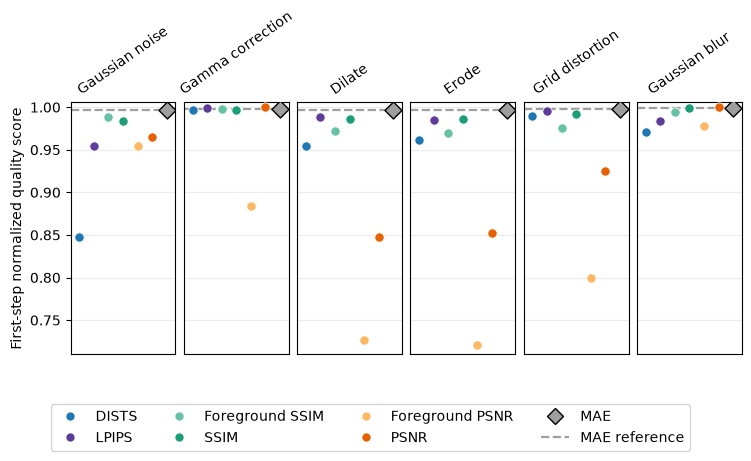

,transform_name,metric_name,clipped_metric_value,normalized_metric_value,mae_normalized_reference,score_difference_from_mae,stronger_response_than_mae
17506,dilate,foreground_psnr,36.357845,0.727157,0.996342,-0.269185,True
17501,dilate,psnr,42.359280,0.847186,0.996342,-0.149156,True
17504,dilate,dists,0.045271,0.954729,0.996342,-0.041613,True
17505,dilate,foreground_ssim,0.971936,0.971936,0.996342,-0.024406,True
17500,dilate,ssim,0.986063,0.986063,0.996342,-0.010279,True
17503,dilate,lpips,0.011696,0.988304,0.996342,-0.008038,True
17502,dilate,mae,0.003658,0.996342,0.996342,0.000000,False
14006,erode,foreground_psnr,36.044914,0.720898,0.996563,-0.275665,True
14001,erode,psnr,42.620277,0.852406,0.996563,-0.144158,True
14004,erode,dists,0.038075,0.961925,0.996563,-0.034638,True


In [8]:
_, step_one_comparison = plot_initial_response_vs_mae(
    normalized_metric_results,
    metric_order=metric_order,
    metric_labels=metric_labels,
    metric_palette=metric_palette,
    transform_order=transform_order,
    transform_labels=transform_labels,
    output_path=plot_output_dir / "iteration_001_metric_response_vs_mae.png",
)
step_one_comparison.sort_values(
    ["transform_name", "score_difference_from_mae"]
)

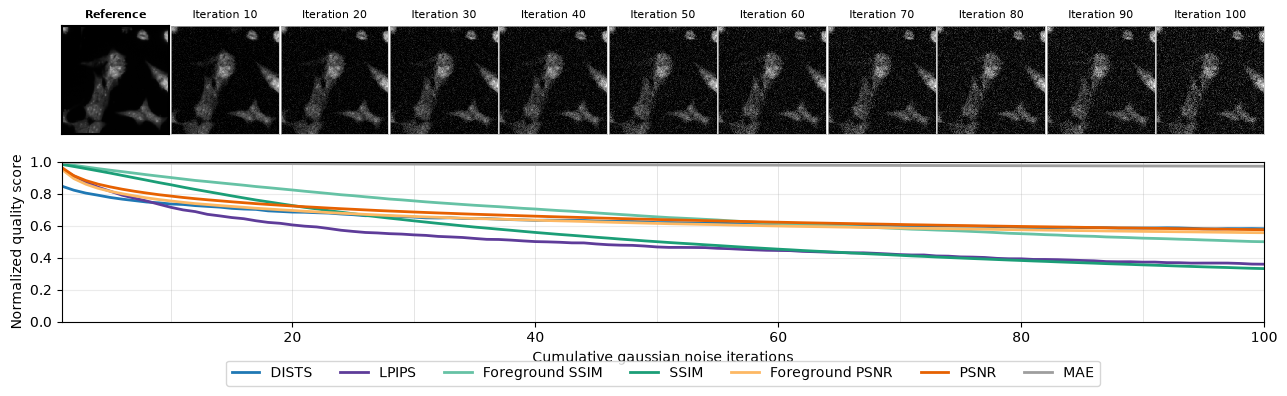

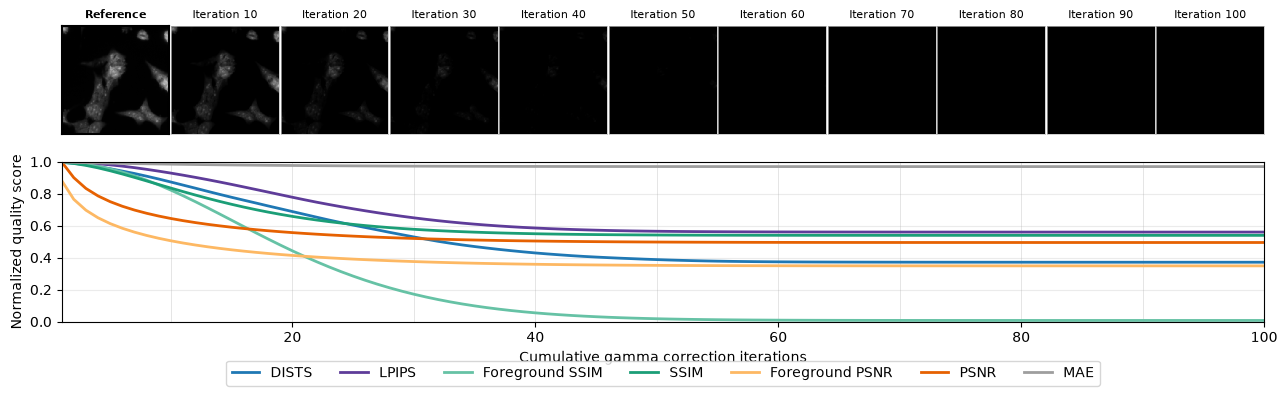

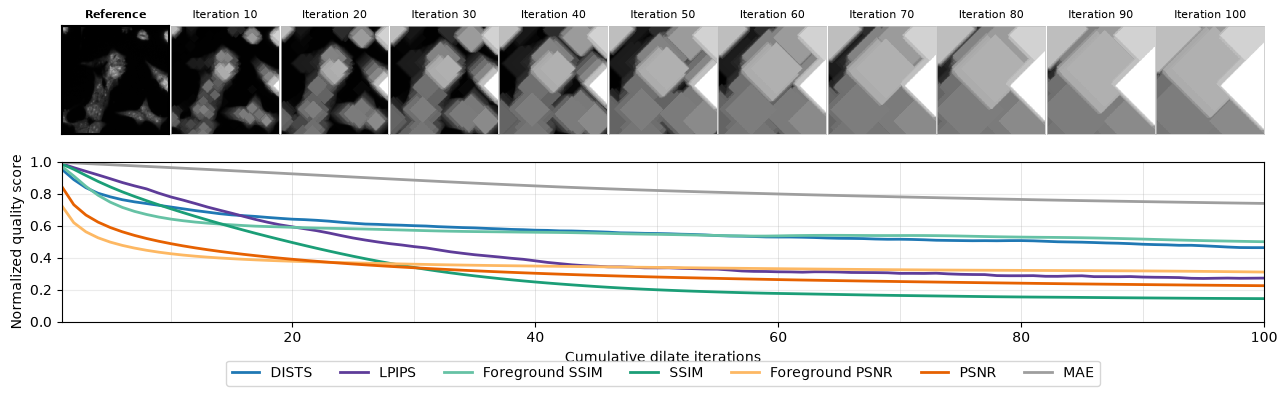

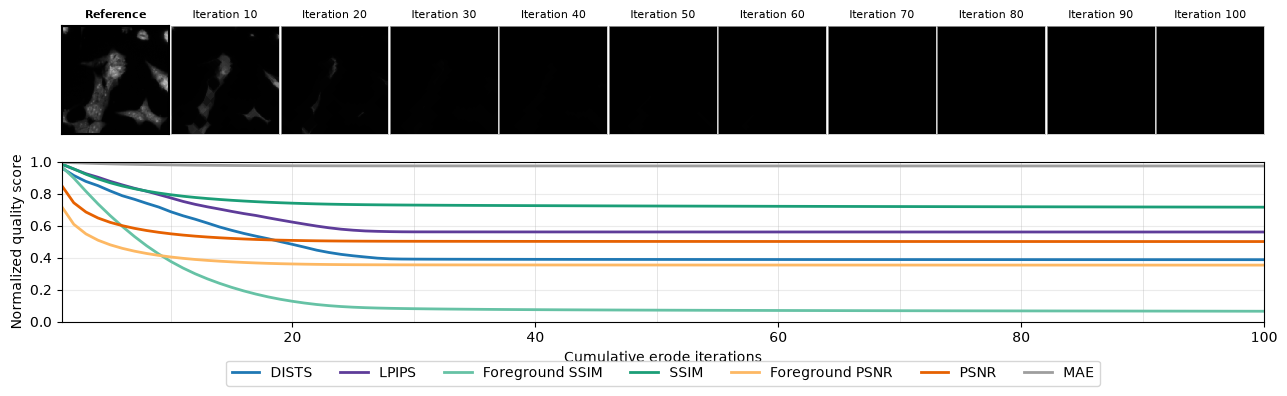

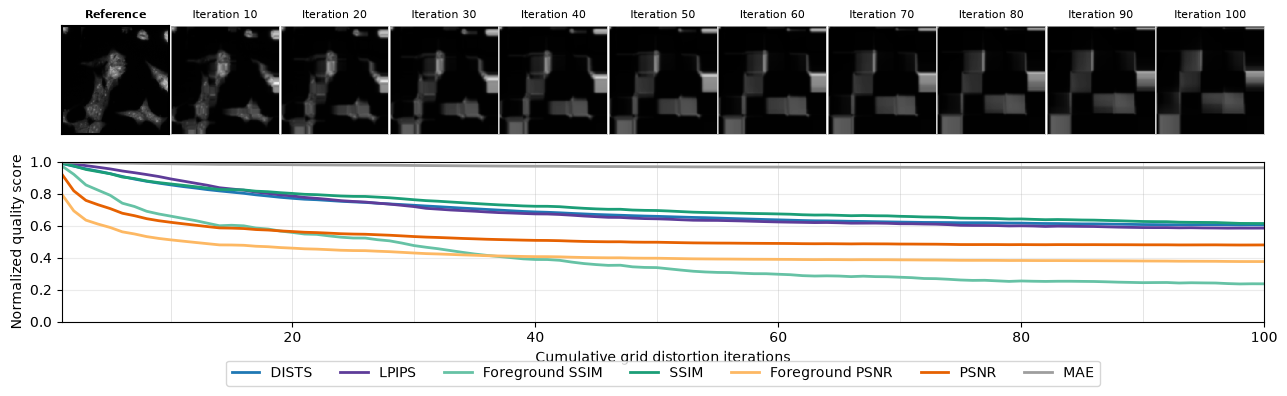

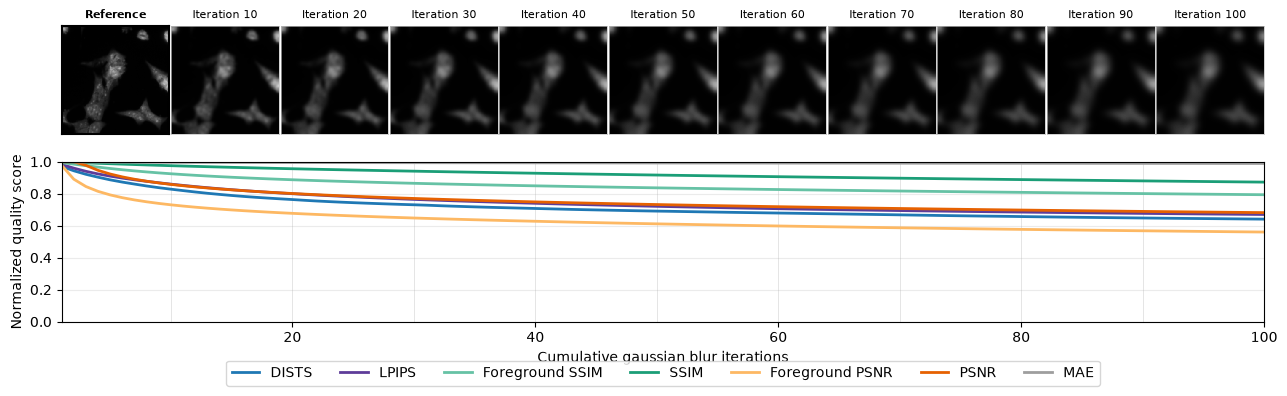

In [9]:
snapshot_limit = min(100, response_configuration["iterations"])
snapshot_interval = response_configuration["snapshot_interval"]
snapshot_iterations = range(
    snapshot_interval,
    snapshot_limit + 1,
    snapshot_interval,
 )

for transform_name in transform_order:
    plot_snapshot_response(
        normalized_metric_results,
        analysis_output_dir,
        transform_name,
        snapshot_iterations,
        metric_order=metric_order,
        metric_labels=metric_labels,
        metric_palette=metric_palette,
        transform_label=transform_labels[transform_name],
        output_path=plot_output_dir / f"{transform_name}_100_it_response_montage.png",
    )